# Case Study 1 : Collecting Data from NewsAPI

Due Date: 11/10/2026, **BEFORE the beginning of class at 12:00pm EST**

## **NOTE: There are *always* last minute issues submitting the case studies.  DO NOT WAIT UNTIL THE LAST MINUTE!**

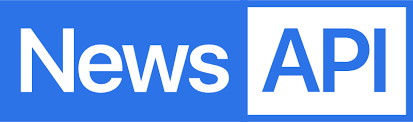

**TEAM Members:** Please EDIT this cell and add the names of all the team members in your team

    Calin Ocnean Sanchez
    
    Jake Dorick

**Suggested Readings:**
* The NewsAPI documentation: https://newsapi.org/docs
* The Python library for NewsAPI: https://newsapi.org/docs/client-libraries/python
* The Python notebook I used in class 3
  * In fact, it is intentional that many of these questions can be answered directly from there (except for question 4)!
* The idea is to ease you into the case studies :-)

**Don't forget!**
* You will need to install the newsapi-python library to access NewsAPI
 * pip install newsapi-python
* You will need to get an API key from NewsAPI to access the data
  * https://newsapi.org/register


** NOTE **
* **Please don't forget to save the notebook frequently when working in IPython Notebook, otherwise the changes you made can be lost**.

# Problem 1 (20 points): Sampling NewsAPI data on a certain topic

* Select a topic that you are interested in, for example, "WPI" or "Lady Gaga"
* Use the NewsAPI to sample a collection of news articles about this topic. (It would be recommended that the number of articles should be larger than 200, but smaller than 100,000.)
* Store the articles you downloaded in a file on Google Drive (txt file or json file)

In [1]:
! pip install newsapi-python


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\jdori\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
from newsapi import NewsApiClient
from dotenv import load_dotenv
import os

load_dotenv(".env", override=True)

# See https://newsapi.org/docs for more information
# on NewsAPI implementation.

API_KEY = os.getenv("API_KEY")

newsapi = NewsApiClient(api_key=API_KEY)
print(newsapi)

In [62]:
results = newsapi.get_everything(q="Texas Senate")
print(results["totalResults"])

4227


### Report some statistics about the news articles you collected

* The topic of interest: 2026 Texas United States Senate Race


* The total number of news articles collected: 4227

*-----------------------

### Store the articles in a .json file to Google Drive

*LLM-Citation:* GitHub Copilot Interactive Chat feature in VSCode accessed through my Github pro account was used to generate and modify code for the cell below. 

In [63]:
import json
import os
from pathlib import Path
from datetime import datetime, timedelta
from newsapi import NewsApiClient
from dotenv import load_dotenv

load_dotenv(override=True)

API_KEY = os.getenv("API_KEY")
newsapi = NewsApiClient(api_key=API_KEY)

# Search the past 30 days
end_date = datetime.now().date()
start_date = end_date - timedelta(days=29)

all_articles = []
seen_urls = set()

current_date = start_date

while current_date <= end_date:

    date_string = current_date.strftime("%Y-%m-%d")

    results = newsapi.get_everything(
        q='"Texas Senate"',
        from_param=date_string,
        to=date_string,
        language="en",
        sort_by="publishedAt",
        page_size=100
    )

    articles = results["articles"]

    for article in articles:
        url = article.get("url")

        if url and url not in seen_urls:
            all_articles.append(article)
            seen_urls.add(url)

    print(f"{date_string}: {len(articles)} articles")

    current_date += timedelta(days=1)

print(f"\nTotal unique articles collected: {len(all_articles)}")

# Save directly to Google Drive
drive_root = Path(os.getenv("GOOGLE_DRIVE_FOLDER")).expanduser()

if not drive_root.is_dir():
    raise FileNotFoundError(f"Google Drive folder not found: {drive_root}")

output_file = drive_root / "texas_senate_articles_new.json"

with output_file.open("w", encoding="utf-8") as file:
    json.dump(all_articles, file, ensure_ascii=False, indent=2)

print(f"Saved {len(all_articles)} articles to {output_file}")

# Display first 5 articles
for index, article in enumerate(all_articles[:5], start=1):
    source = article.get("source") or {}

    print(f"\n{index}. {article.get('title') or 'Untitled'}")
    print(f"   Source: {source.get('name') or 'Unknown source'}")
    print(f"   Published: {article.get('publishedAt') or 'Unknown'}")
    print(f"   URL: {article.get('url') or 'Unavailable'}")

2026-10-09: 30 articles
2026-10-10: 10 articles
2026-10-11: 8 articles
2026-10-12: 24 articles
2026-10-13: 40 articles
2026-10-14: 29 articles
2026-10-15: 22 articles
2026-10-16: 32 articles
2026-10-17: 6 articles
2026-10-18: 5 articles
2026-10-19: 14 articles
2026-10-20: 13 articles
2026-10-21: 18 articles
2026-10-22: 17 articles
2026-10-23: 12 articles
2026-10-24: 6 articles
2026-10-25: 5 articles
2026-10-26: 4 articles
2026-10-27: 20 articles
2026-10-28: 21 articles
2026-10-29: 18 articles
2026-10-30: 24 articles
2026-10-31: 9 articles
2026-11-01: 9 articles
2026-11-02: 19 articles
2026-11-03: 27 articles
2026-11-04: 97 articles
2026-11-05: 33 articles
2026-11-06: 9 articles
2026-11-07: 0 articles

Total unique articles collected: 581
Saved 581 articles to G:\My Drive\texas_senate_articles_new.json

1. Willie Nelson, Yo La Tengo Endorse James Talarico
   Source: Pitchfork
   Published: 2026-10-09T21:54:32Z
   URL: https://pitchfork.com/story/willie-nelson-yo-la-tengo-endorse-james-t

Working around the API call limits in the free developer mdoe, 581 results are saved to the .json file in Google Drive.

# Problem 2 (20 points): Analyzing News Articles with Frequency Analysis

**1. Word Count:**
* Use the news articles you collected in Problem 1, and compute the frequencies of the words being used in these articles.
* Note, you can use various parts of the articles (e.g. the title, the description, the content) to compute the word frequencies.
  * Which is most useful?
* Plot a table of the top 30 words with their counts

*LLM-Citation:* GitHub Copilot was used to generate and modify code for the cell below. 

In [ ]:
from collections import Counter
from pathlib import Path
import json
import re
import pandas as pd

# Load the articles from the updated JSON file in the repository folder added from Google Drive
json_file = Path("texas_senate_articles_new.json")

with json_file.open("r", encoding="utf-8") as file:
    all_articles = json.load(file)

# Specify which article fields to include in the word count
text_fields = ("title", "description", "content") # Not including author name
word_counts = Counter()

# Iterate through the articles and extract words from the selected fields
for article in all_articles:
    text_parts = [
        article[field]
        for field in text_fields
        if isinstance(article.get(field), str)
    ]

    # Include the news source name in the word count, if available
    source = article.get("source")

    if isinstance(source, dict) and isinstance(source.get("name"), str):
        text_parts.append(source["name"])

    # Combine the text fields into one string
    text = " ".join(text_parts)

    # Remove NewsAPI truncation markers (such as [+540 chars])
    text = re.sub(r"\[\+\d+\s+chars?\]", "", text, flags=re.IGNORECASE)

    # Normalize curly apostrophes to standard apostrophes
    text = text.replace("’", "'").replace("‘", "'")

    # Remove possessive endings that could create standalone "s" tokens
    text = re.sub(r"'s\b", "", text, flags=re.IGNORECASE)

    # Extract lowercase words while preserving other contractions
    words = re.findall(r"\b[a-z]+(?:'[a-z]+)*\b", text.lower())

    word_counts.update(words)

# Create a DataFrame containing the 30 most frequently occurring words
top_words = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "count"]
)

# Display the most common words
display(top_words)

,word,count
0,the,2119
1,in,1151
2,a,898
3,to,886
4,of,850
5,texas,842
6,and,721
7,senate,688
8,talarico,595
9,on,528


*No LLM or generative AI was used in the response below.*

The most useful parts of the article to compute word frequencies would be the title, description, and content. Those three sections contain the majority of words related to the article itself. The author name and source name do not relate to the content of the article (or are only slightly related, such as a political source publishing a political article). Arguably, the most important part of the article for word frequency distribution would be the title, as it is likely the author would include less filler words in order to address the takeaway of the article as quickly as possible.

**2. Find the most popular news sources and authors in your articles**

* Please provide a table of the top 10 authors and sources that are the most popular among your collection.


*LLM-Citation:* GitHub Copilot was used to generate and modify code for the cell below. 

In [70]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

import json
from pathlib import Path
from collections import Counter
import pandas as pd

# Load the articles from the updated JSON file in the repository folder
json_file = Path("texas_senate_articles_new.json")

with json_file.open("r", encoding="utf-8") as file:
    all_articles = json.load(file)

# Initialize counters to track how many articles come from each source and author
source_counts = Counter()
author_counts = Counter()

# Iterate through the collected articles and extract their sources and authors
for article in all_articles:
    # Extract the news source name, if available, and increase its count
    source = article.get("source") or {}
    source_name = source.get("name") if isinstance(source, dict) else None

    if isinstance(source_name, str) and source_name.strip():
        source_counts[source_name.strip()] += 1

    # Extract the author's name, if available, and increase its count
    author = article.get("author")

    if isinstance(author, str) and author.strip():
        author_counts[author.strip()] += 1

# Convert the most common news sources into a DataFrame
top_sources = pd.DataFrame(
    source_counts.most_common(10),
    columns=["News Source", "Article Count"]
)

# Convert the most common authors into a DataFrame
top_authors = pd.DataFrame(
    author_counts.most_common(10),
    columns=["Author", "Article Count"]
)

# Display the most common news sources and authors
print(f"Total articles analyzed: {len(all_articles)}")

display(top_sources)
display(top_authors)

Total articles analyzed: 581


,News Source,Article Count
0,Biztoc.com,40
1,The Times of India,39
2,Slashdot.org,34
3,Fox News,30
4,Dailymail.com,26
5,The Daily Caller,20
6,Freerepublic.com,18
7,Mediaite,17
8,Raw Story,17
9,Crypto Briefing,12


,Author,Article Count
0,feedfeeder,34
1,Nicole Silverio,17
2,newsweek.com,14
3,Estefano Gomez,12
4,HuffPost,10
5,Travis Gettys,8
6,ET Online,8
7,youtube.com,6
8,Samantha Loren,5
9,Ryan Bort,5


**3. What is the lexical diversity in your descriptions and contents**

* For two popular authors or two popular **sources**, please compare the lexical diversity of their descriptions and contents.  
Which one is more diverse?  
  * Open ended questions: Does this make sense?  Why or why not? What might lexical diversity tell us about the author or source?

*LLM-Citation:* GitHub Copilot was used to generate and modify code for the cell below. 

In [76]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

import json
import re
import pandas as pd
from pathlib import Path
from collections import Counter

# Load the articles from the updated JSON file in the repository folder
json_file = Path("texas_senate_articles_new.json")

with json_file.open("r", encoding="utf-8") as file:
    all_articles = json.load(file)

# Calculate lexical diversity using the combined text from a news source
def lexical_diversity(texts):
    words = re.findall(r"[a-z]+", " ".join(texts).lower())
    return len(set(words)) / len(words) if words else None, len(set(words)), len(words)

# Count how many articles come from each news source
source_counts = Counter()

for article in all_articles:
    # Extract the news source name, if available, and increase its count
    source = article.get("source") or {}

    if isinstance(source, dict) and isinstance(source.get("name"), str):
        source_counts[source["name"].strip()] += 1

# Identify the two news sources with the most articles
popular_sources = [name for name, _ in source_counts.most_common(2)]
diversity_rows = []

# Calculate lexical diversity separately for descriptions and content from each source
for source_name in popular_sources:
    # Collect all articles belonging to the current news source
    source_articles = [
        article for article in all_articles
        if isinstance(article.get("source"), dict)
        and isinstance(article["source"].get("name"), str)
        and article["source"]["name"].strip() == source_name
    ]

    # Calculate lexical diversity for descriptions and content separately
    for field in ("description", "content"):
        # Collect all available text for the current field
        texts = [
            article[field]
            for article in source_articles
            if isinstance(article.get(field), str) and article[field].strip()
        ]

        # Calculate lexical diversity, unique words, and total words
        diversity, unique_words, total_words = lexical_diversity(texts)

        # Store the results for the current source and text field
        diversity_rows.append({
            "source": source_name,
            "field": field,
            "articles_with_text": len(texts),
            "unique_words": unique_words,
            "total_words": total_words,
            "lexical_diversity": diversity,
        })

# Convert the results into a DataFrame
diversity_table = pd.DataFrame(diversity_rows)

# Display the lexical diversity results
print("Lexical diversity = number of unique words / total words, calculated across each source's available text.")
display(diversity_table)

Lexical diversity = number of unique words / total words, calculated across each source's available text.


,source,field,articles_with_text,unique_words,total_words,lexical_diversity
0,Biztoc.com,description,40,572,1454,0.393398
1,Biztoc.com,content,40,499,1283,0.388932
2,The Times of India,description,39,612,1239,0.493947
3,The Times of India,content,39,422,1374,0.307132


*No LLM or generative AI was used in the response below.*

The more diverse source is The Times of India. The Times of India has a total lexical diversity (the sum of unique words in the description and content divided by the total number of words in both sections) of 0.3957. Biztoc.com has a total lexical diversity of 0.3913. 

The results make sense because the lexical diversity of the description should be greater than that of the content, as seen with both sources. Similarly to an article's title, its description is less likely to include filler words in order to address the takeaway of the article as quickly as possible. For Biztoc.com, the lexical diversity of the description is only slightly greater than that of the content, but for The Times of India, it is approximately +0.187. While I am unfamiliar with both of these sources, comparing the lexical diversity shows how each of the sources distributes its articles' central concepts. That is to say, since The Times of India has a greater lexical diversity in its description rather than its content, the source is likely more able to get its point across quickly in its description rather than having a lot of filler words. Conversely, Biztoc.com may be more reader-friendly as its lexical diversity is consistent across their articles' descriptions and content. 

* ------------------------

# Problem 3 (20 points): Image processing


* For each news article, download the image associated with it (using the urlToImage field).
* Do these images tell you anything about the news articles?  If so, what?

In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary




* Let's automate the process!  Use Hugging Face's transformers library to download a pre-trained image segmentation model.
  * See my notebook from class 3 for an example of how to do this.
* Open ended question: Collect statistics on what appears in the images for your news articles? What does this tell you?

In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary




*------------------------

# Problem 4 (20 points): Business question

Run some additional experiments with your data to gain familiarity with the NewsAPI.

* Come up with a business question that NewsAPI data could help answer.
* Describe the business case.
* How could NewsAPI data help a company decide how to spend its resources.
* **[LLM only]** Ask your favorite LLM to provide three business ideas that this data could support and provide those ideas as part of your report.
* **[Human only]** Analyze those three ideas and come up with an idea for a product that you will form the organizing center for you work in the rest of the case studies.
* **[LLM only]**: Ask the LLM to act as a potential buyer and identify three reasons someone might not use your selected product.
* **[Human only]**: Decide which objection matters most. Propose a small experiment to test it, specify what you would measure, and define a result that would make you revise or cancel the idea.


In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary





*-----------------
# Done

All set!

** What do you need to submit?**

* **Notebook File**: Save this IPython notebook, and find the notebook file in your folder (for example, "filename.ipynb"). This is the file you need to submit. Please make sure all the plotted tables and figures are in the notebook. If you used "ipython notebook --pylab=inline" to open the notebook, all the figures and tables should have shown up in the notebook.
**Also, you must cite any LLM assistance and any other support you get for the project.**




* **Report**: please prepare a report (less than 10 pages) to report what you found in the data.
    * What data you collected?
    * Why this topic is interesting or important to you? (Motivations)
    * How did you analyse the data?
    * What did you find in the data?


     (please include figures or tables in the report, but no source code)

* **Video**: A 2–3-minute video pitch to a Venture Capitalist. This should discuss the data you gathered, the topic of interest, the methodology you used to gather the data, and provide a preview of your product. **Submit only a link to your video, not the video file. Include the link to your video in your report file. You may upload your video to Google Drive, OneDrive, YouTube (Unlisted) or any other video-sharing platform. Ensure that anyone with the shared link can view the video without requesting access.**

Please compress the notebook file and the report (including the video link) into a zipped file and submit it on canvas.wpi.edu for grading.



# Grading Criteria:

** Total Points: 100 **


---------------------------------------------------------------------------
** Notebook results:  **
    Points: 80


    -----------------------------------
    Question 1:
    Points: 20
    -----------------------------------
    
    (1) Select a topic that you are interested in.
    Points: 6
    
    (2) Use the NewsAPI to sample a collection of news articles about this topic. (It would be recommended that the number of articles should be larger than 200, but smaller than 100,000. Please check whether the total number of articles collected is larger than 200.)
    Points: 10
    
    
    (3) Store the articles you downloaded into a file on Google Drive (txt file or json file)
    Points: 4
    
    
    -----------------------------------
    Question 2:
    Points: 20
    -----------------------------------
    
    1. Word Count

    (1) Use the news articles you collected in Problem 1, and compute the frequencies of the words being used in these articles.
    Points: 5

    (2) Plot a table of the top 30 words with their counts
    Points: 5
    
    2. Please provide a table of the top 10 authors and sources that are the most popular among your collection.
    Points: 5
    
    3. For two popular authors or two popular sources, please compare the lexical diversity of their descriptions and contents.
    Points: 5
      
    -----------------------------------
    Question 3:
    Points: 20
    -----------------------------------
    
    (1) For each news article, download the image associated with it (using the urlToImage field).
    Points: 10

    (2) Use Hugging Face's transformers library to download a pre-trained image segmentation model.
    Points: 10
  
    -----------------------------------
    Question 4:  Business question
    Points: 20
    -----------------------------------
        Novelty: 10
        Interestingness: 10
    -----------------------------------
    Run some additional experiments with your data to gain familiarity with the NewsAPI.  Come up with a business question and describe how NewsAPI data can help you answer that question.

    -----------------------------------
    Report and video:  
    Points: 20
    -----------------------------------
    


